In [29]:
##plotting when was the best time to make jokes using visualization 2-defined function
import sys
import os
from pathlib import Path
import pandas as pd
import numpy as np
import scipy.stats as stats
from math import floor
import matplotlib.pyplot as plt
import plotly.express as px 
from pathlib import Path
from matplotlib.image import imread
import json
from datetime import datetime, timedelta
import nbimporter
import plotly.express as px
# Get path to the project root: project/
PROJECT_ROOT = Path.cwd().parents[1]

# Add src/ to Python path
SRC_DIR = PROJECT_ROOT / "src"

sys.path.append(str(SRC_DIR))
print("Folders in SRC_DIR:", list(SRC_DIR.iterdir()))
#from Milestone_P2.utils.visualization2 import plot_number_of_captions_vs_contests



Folders in SRC_DIR: [WindowsPath('c:/Users/hanna/ADA/ada-2025-project-json-derulo/src/Adrian'), WindowsPath('c:/Users/hanna/ADA/ada-2025-project-json-derulo/src/Hanna'), WindowsPath('c:/Users/hanna/ADA/ada-2025-project-json-derulo/src/Jeremy'), WindowsPath('c:/Users/hanna/ADA/ada-2025-project-json-derulo/src/Mariem'), WindowsPath('c:/Users/hanna/ADA/ada-2025-project-json-derulo/src/Milestone_P2')]


In [3]:

FIGURES_DIR = PROJECT_ROOT / 'figures'

# DATA DIRECTORIES
DATA_DIR = PROJECT_ROOT / 'data' / 'newyorker_caption_contest'
JSON_DIR = DATA_DIR / 'contests.json'
CSV_DIR = DATA_DIR / 'data'
CSV_CLEAN_DIR = DATA_DIR / 'data_cleaned'
IMG_DIR = DATA_DIR / 'images'

print("Project path setup:")
print("PROJECT_ROOT:  ", PROJECT_ROOT)
print("SRC DIR     :" , SRC_DIR)
print("FIGURES_DIR:   ", FIGURES_DIR)
print("\nDATA_DIR:      ", DATA_DIR)
print("JSON_DIR:      ", JSON_DIR)
print("CSV_DIR:       ", CSV_DIR)
print("CSV_CLEAN_DIR: ", CSV_CLEAN_DIR)
print("IMG_DIR:       ", IMG_DIR)

Project path setup:
PROJECT_ROOT:   c:\Users\hanna\ADA\ada-2025-project-json-derulo
SRC DIR     : c:\Users\hanna\ADA\ada-2025-project-json-derulo\src
FIGURES_DIR:    c:\Users\hanna\ADA\ada-2025-project-json-derulo\figures

DATA_DIR:       c:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest
JSON_DIR:       c:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\contests.json
CSV_DIR:        c:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\data
CSV_CLEAN_DIR:  c:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\data_cleaned
IMG_DIR:        c:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\images


In [4]:
def plot_number_of_captions_vs_contests(folder_path,image_path):
    folder_path=str(folder_path)
    contest_counts = {} #intialise caption number at 0
    if not os.path.isdir(folder_path):
        raise FileNotFoundError(f"Folder not found: {folder_path}") #missing contests
    for contest_num in range(510, 896):
        filename = f"{contest_num}_cleaned.csv" #added _cleaned to make it work in new dataset
        file_path = os.path.join(folder_path, filename)
        if os.path.exists(file_path):
            try:
                df = pd.read_csv(file_path)
                contest_counts[contest_num] = len(df) #to get the length of the file = number of captions per contest
            except Exception as e:
                print(f"Error reading {filename}: {e}")
        else:
            print(f"File not found: {filename}")

    # Turning them into Dataframes
    counts_df = pd.DataFrame(list(contest_counts.items()), columns=["Contest", "Num_Captions"])
    counts_df = counts_df.sort_values(by="Num_Captions", ascending=False) #ordered list of the contest with their corresponding number of captions

    # printing the gist of the top and least populars
    print("\nTop 5 most popular contests:")
    print(counts_df.head())

    print("\nTop 5 least popular contests:")
    print(counts_df.tail())

    # Defining the top and least popular
    most_popular = counts_df.iloc[0]
    least_popular = counts_df.iloc[-1]

    print(f"\nMost popular contest: #{most_popular['Contest']} with {most_popular['Num_Captions']} captions.")
    print(f"Least popular contest: #{least_popular['Contest']} with {least_popular['Num_Captions']} captions.")

    # Visualizing
    plt.figure(figsize=(10,5))
    plt.scatter(counts_df["Contest"], counts_df["Num_Captions"], marker='o', linestyle='-')
    # Highlight most & least popular on the scatter plot
    plt.scatter(most_popular["Contest"], most_popular["Num_Captions"], color='green', s=100, label='Most popular')
    plt.scatter(least_popular["Contest"], least_popular["Num_Captions"], color='red', s=100, label='Least popular')

    plt.annotate(f"{int(most_popular['Contest'])}",
                xy=(most_popular['Contest'], most_popular['Num_Captions']),
                xytext=(most_popular['Contest'], most_popular['Num_Captions'] + 100),
                arrowprops=dict(facecolor='green', arrowstyle='->'),
                fontsize=10)

    plt.annotate(f"{int(least_popular['Contest'])}",
                xy=(least_popular['Contest'], least_popular['Num_Captions']),
                xytext=(least_popular['Contest'], least_popular['Num_Captions'] - 100),
                arrowprops=dict(facecolor='red', arrowstyle='->'),
                fontsize=10)
    plt.title("Number of Captions per Contest")
    plt.xlabel("Contest Number")
    plt.ylabel("Number of Captions")
    plt.grid(True)
    plt.show()

In [24]:
def add_contest_dates(df):
    """
    Adds publish and vote dates for each contest based on weekly frequency.
    Contest 510 is assumed to be published on 22 Feb 2016.
    """

    base_publish = datetime.strptime('2016.02.22', "%Y.%m.%d")

    publish_dates = []
    vote_dates = []

    for i in range(len(df)):
        contest_id = df['contest_id'].iloc[i]
        diff = int(contest_id) - 510

        publish_date = base_publish + timedelta(days=diff * 7)
        vote_date = publish_date + timedelta(days=7)

        # Ensure metadata is a dictionary
        if df.at[i, 'metadata'] is None:
            df.at[i, 'metadata'] = {}

        # Now safe to assign
        df.at[i, 'metadata']['contest_day_publish'] = publish_date
        df.at[i, 'metadata']['contest_day_votes'] = vote_date

        publish_dates.append(publish_date)
        vote_dates.append(vote_date)

    df['contest_day_publish'] = publish_dates
    df['contest_day_votes'] = vote_dates

    return df

Error reading 523_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 492, saw 10

File not found: 525_cleaned.csv
File not found: 540_cleaned.csv
Error reading 625_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 152, saw 12

Error reading 648_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 2593, saw 9

Error reading 649_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 3324, saw 9

Error reading 652_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 9510, saw 9

Error reading 653_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 5587, saw 9

Error reading 756_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 7037, saw 9

Error reading 767_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 7320, saw 10

Error reading 841_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 3334, saw 9

Error reading 855

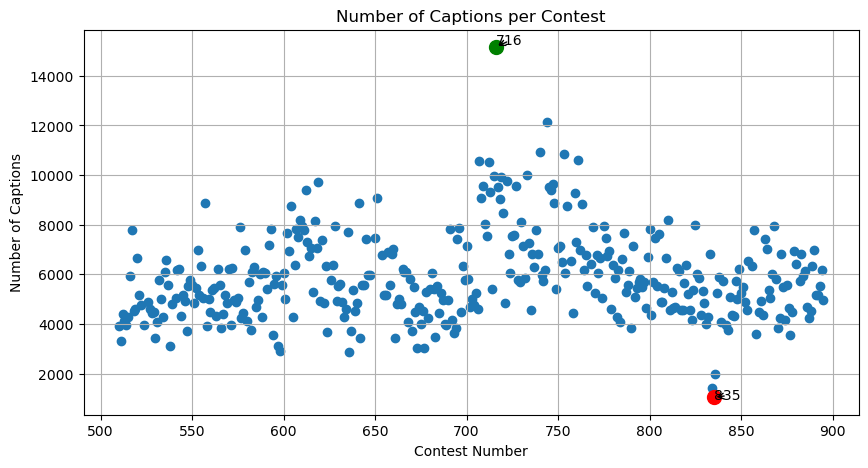

In [18]:
plot_number_of_captions_vs_contests(CSV_CLEAN_DIR, IMG_DIR)
#C:\Users\hanna\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\data_cleaned

In [25]:
contest_no_dates = pd.read_json(JSON_DIR)
contest_no_dates.head()



,contest_id,image,data,metadata
0,510,images/510.jpg,data/510.csv,"{'num_captions': 3905, 'num_votes': 41185, 'im..."
1,511,images/511.jpg,data/511.csv,"{'num_captions': 3325, 'num_votes': 28205, 'im..."
2,512,images/512.jpg,data/512.csv,"{'num_captions': 4399, 'num_votes': 21574, 'im..."
3,513,images/513.jpg,data/513.csv,"{'num_captions': 4141, 'num_votes': 16894, 'im..."
4,514,images/514.jpg,data/514.csv,"{'num_captions': 3951, 'num_votes': 95790, 'im..."


In [ ]:
contest_with_dates = add_contest_dates(contest_no_dates)
contest_with_dates

In [27]:
def plot_captions_timeline(folder_path, contest_with_dates):
    folder_path = str(folder_path)
    contest_counts = {}

    # Count captions per contest
    for contest_num in range(510, 896):
        filename = f"{contest_num}_cleaned.csv"
        file_path = os.path.join(folder_path, filename)

        if os.path.exists(file_path):
            try:
                df = pd.read_csv(file_path)
                contest_counts[contest_num] = len(df)
            except Exception as e:
                print(f"Error reading {filename}: {e}")

    # Create DataFrame
    counts_df = pd.DataFrame(list(contest_counts.items()),
                             columns=["Contest", "Num_Captions"])

    # Merge with publish dates
    merged = counts_df.merge(
        contest_with_dates[['contest_id', 'contest_day_publish']],
        left_on='Contest',
        right_on='contest_id',
        how='inner'
    )

    merged = merged.sort_values(by="contest_day_publish")  # ensure chronological

    # Plot time series
    plt.figure(figsize=(12, 6))
    plt.plot(merged["contest_day_publish"], merged["Num_Captions"])
    plt.scatter(merged["contest_day_publish"], merged["Num_Captions"])

    plt.title("Timeline of Contest Popularity (Number of Captions Over Time)")
    plt.xlabel("Publish Date")
    plt.ylabel("Number of Captions")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return merged


Error reading 523_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 492, saw 10

Error reading 625_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 152, saw 12

Error reading 648_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 2593, saw 9

Error reading 649_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 3324, saw 9

Error reading 652_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 9510, saw 9

Error reading 653_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 5587, saw 9

Error reading 756_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 7037, saw 9

Error reading 767_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 7320, saw 10

Error reading 841_cleaned.csv: Error tokenizing data. C error: Expected 8 fields in line 3334, saw 9

Error reading 855_cleaned.csv: Error tokenizing data. C error: Expected 8 fields 

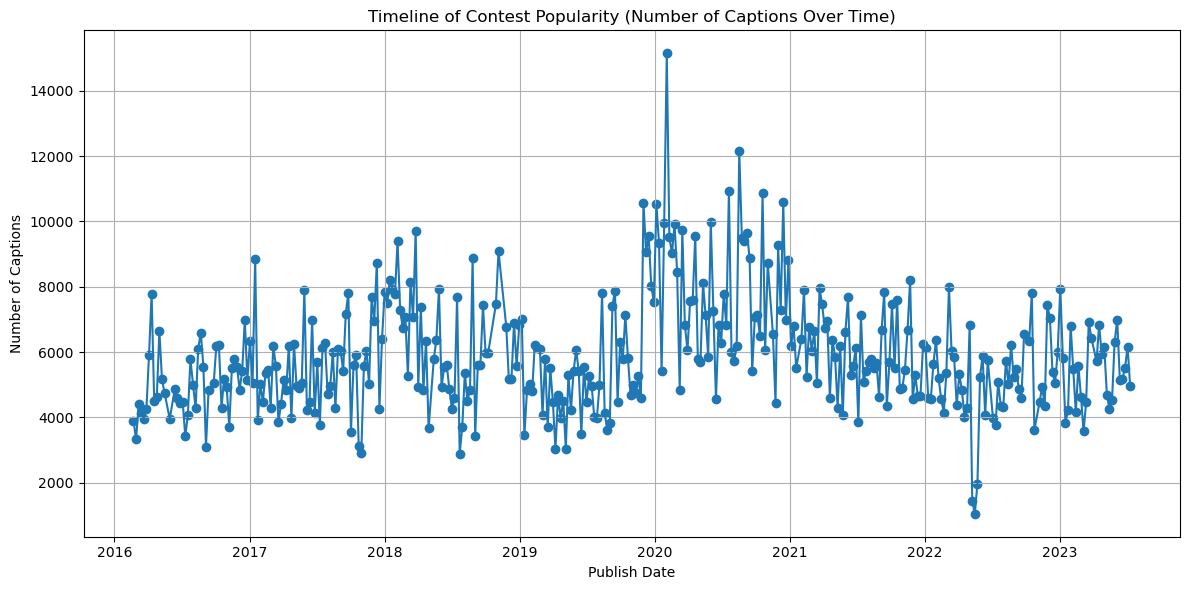

,Contest,Num_Captions,contest_id,contest_day_publish
0,510,3905,510,2016-02-22
1,511,3325,511,2016-02-29
2,512,4399,512,2016-03-07
3,513,4141,513,2016-03-14
4,514,3951,514,2016-03-21
...,...,...,...,...
367,891,5159,891,2023-06-12
368,892,5188,892,2023-06-19
369,893,5513,893,2023-06-26
370,894,6157,894,2023-07-03


In [28]:
plot_captions_timeline(CSV_CLEAN_DIR, contest_with_dates)

NOW AS PLOTLY

In [30]:
def plot_number_of_captions_vs_contests_plotly(folder_path, contest_with_dates):
    folder_path = str(folder_path)
    contest_counts = {}

    # Count captions per contest
    for contest_num in range(510, 896):
        filename = f"{contest_num}_cleaned.csv"
        file_path = os.path.join(folder_path, filename)

        if os.path.exists(file_path):
            try:
                df = pd.read_csv(file_path)
                contest_counts[contest_num] = len(df)
            except:
                pass

    # Build dataframe
    counts_df = pd.DataFrame(list(contest_counts.items()),
                             columns=["Contest", "Num_Captions"])

    # Merge publish dates
    merged = counts_df.merge(
        contest_with_dates[['contest_id', 'contest_day_publish']],
        left_on='Contest',
        right_on='contest_id',
        how='inner'
    ).sort_values(by="contest_day_publish")

    # Plot with Plotly
    fig = px.line(
        merged,
        x="contest_day_publish",
        y="Num_Captions",
        markers=True,
        title="Timeline of Contest Popularity (Number of Captions Over Time)"
    )

    fig.update_layout(
        xaxis_title="Publish Date",
        yaxis_title="Number of Captions",
        template="plotly_white"
    )

    fig.show()

    return merged

In [31]:
plot_number_of_captions_vs_contests_plotly(CSV_CLEAN_DIR, contest_with_dates)

,Contest,Num_Captions,contest_id,contest_day_publish
0,510,3905,510,2016-02-22
1,511,3325,511,2016-02-29
2,512,4399,512,2016-03-07
3,513,4141,513,2016-03-14
4,514,3951,514,2016-03-21
...,...,...,...,...
367,891,5159,891,2023-06-12
368,892,5188,892,2023-06-19
369,893,5513,893,2023-06-26
370,894,6157,894,2023-07-03
